<a href="https://colab.research.google.com/github/edavidbustosp/AplicacionesDeepLearning/blob/main/DeteccionFraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Detección de Fraude Mediante Deep Learning**
Proyecto desarrollado por:

Ing. Edgar David Bustos Pulido

Aplicaciones de Deep Learning



#**Primer Avance**

Implementación inicial del modelo,

* Pruebas experimentales

* Análisis de resultados

* Propuesta de rediseño.


Importación de Librerías

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import TensorDataset, DataLoader

Configuraciones

In [2]:
#Configuración de visualización
sns.set_theme(style="whitegrid")

#Configuración de reproducibilidad

SEED=42

np.random.seed(SEED)
torch.manual_seed(SEED)

#Dispositivo de ejecución
device=torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo de ejecución: ", device)
print("Versión de Pythorch: ", torch.__version__)


Dispositivo de ejecución:  cuda
Versión de Pythorch:  2.14.1+cu130


Carga del dataset

In [3]:
from google.colab import files
from io import BytesIO

uploaded=files.upload()

archivo=next(iter(uploaded))

df=pd.read_csv(BytesIO(uploaded[archivo]))

print("Dataset cargado correctamente")
print("Dimensiones: ",df.shape)

display(df.head())

Saving creditcard.csv to creditcard.csv
Dataset cargado correctamente
Dimensiones:  (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#**Analisis Exploratorio Inicial**

Información general del dataset
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19

,Cantidad,Porcentaje
Legitimas (0),284315,99.827251
Fraudulentas (1),492,0.172749


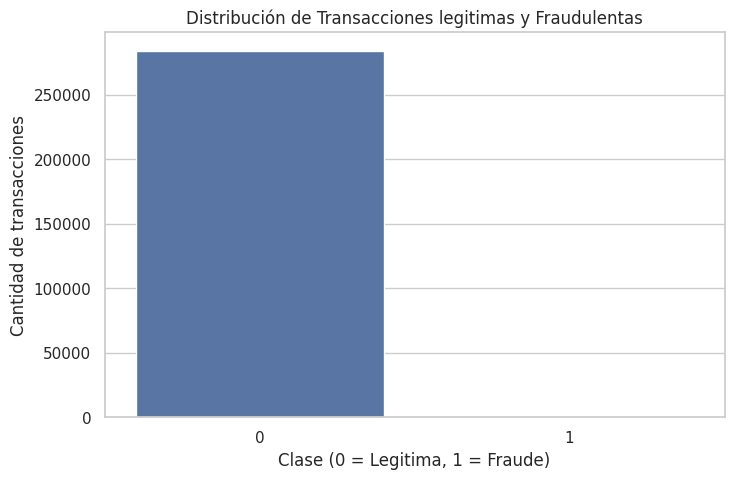


Estadísticas descriptivas
--------------------------------------------------


,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


In [4]:
# ======================================
# ANÁLISIS EXPLORATORIO DEL DATASET
# ======================================

#1. Información general

print("Información general del dataset")
print("-" * 50)

df.info()


#2. Verificación de valores nulos

print("\nValores Nulos")
print("-" * 50)

print("Total de valores nulos: ", df.isnull().sum().sum())

#3. Verificación de registros duplicados

print("\nRegistros duplicados")
print("-" * 50)

print("Cantidad de duplicados: ", df.duplicated().sum())

#4. Distribución de las clases
print("\nDistribución de las clases")
print("-" * 50)

conteo_clases=df["Class"].value_counts().sort_index()
porcentaje_clases=df["Class"].value_counts(normalize=True).sort_index()*100

distribucion=pd.DataFrame({
    "Cantidad":conteo_clases,
    "Porcentaje":porcentaje_clases
})

distribucion.index=["Legitimas (0)", "Fraudulentas (1)"]

display(distribucion)

#5. Validación del desequilibrio
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribución de Transacciones legitimas y Fraudulentas")
plt.xlabel("Clase (0 = Legitima, 1 = Fraude)")
plt.ylabel("Cantidad de transacciones")

plt.show()


#6. Estadísticas descriptivas
print("\nEstadísticas descriptivas")
print("-" * 50)

display(df[["Time", "Amount"]].describe())



#**Estado Actual del desarrollo**
Al cierre de esta primera etapa de trabajo se han completado las siguientes actividades:
- [OK] Selección de la fuente de información.
- [OK] Configuración del entorno de Google Colab.
- [OK] Verificación de disponibilidad de GPU mediante CUDA.
- [OK] Importación de las librerías principales.
- [OK] Carga del archivo creditcard.csv.
- [OK] Inspección de la estructura y dimensiones del dataset.
- [OK] Verificación de valores nulos.
- [OK] Identificación de registros duplicados.
- [OK] Análisis inicial de la distribución de las clases.
- [OK] Obtención de estadísticas descriptivas de las variables Time y Amount.
- [ ] Tratamiento y preparación de los datos.
- [ ] División de los datos en entrenamiento, validación y prueba.
- [ ] Implementación de la arquitectura de Deep Learning.
- [ ] Entrenamiento y evaluación del modelo inicial.
- [ ] Análisis de resultados y propuesta de rediseño.

#**Segundo Avance**

#**Análisis de Registros Duplicados**
Se tienen identificados una cantidad "n" de registros duplicados pero antes de saber si eliminarlos o no se debe saber como se distribuyen dentro de las transacciones legitimas y fraudulentas.


In [5]:
# =======================================
# Análisis de Registros Duplicados
# =======================================

# Identificar todos los registros duplicados

duplicados=df[df.duplicated(keep=False)].copy()

print("Análisis de Duplicados")
print("-" * 50)

print("Total de filas duplicadas:",df.duplicated().sum())
print("Total de filas involucradas en grupos duplicados:", len(duplicados))

# Distribución de clases en los registros duplicados
print("\nDistribución de clases en los duplicados")

display(
    duplicados["Class"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Legitimas (0)",
        1: "Fraudulentas (1)"
    })
)

#comparar duplicados con el conjunto completo
print("\nDistribución Porcentual")

display(
    pd.DataFrame({
        "Dataset completo (%)": df["Class"].value_counts(normalize=True) * 100,
        "Registros duplicados (%)": duplicados["Class"].value_counts(normalize=True) * 100
    }).fillna(0)
)

# Mostrar ejemplos

print("\nEjemplos de registros duplicados")

display(duplicados.head(10))

Análisis de Duplicados
--------------------------------------------------
Total de filas duplicadas: 1081
Total de filas involucradas en grupos duplicados: 1854

Distribución de clases en los duplicados


,count
Class,
Legitimas (0),1822
Fraudulentas (1),32



Distribución Porcentual


,Dataset completo (%),Registros duplicados (%)
Class,,
0,99.827251,98.274002
1,0.172749,1.725998



Ejemplos de registros duplicados


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


#**Deteminar cuantos registros se perderan al eliminar duplicados**



In [6]:
# =========================================================
# Evaluación del impacto de eliminar registros duplicados
# =========================================================

#Identificación de las filas que se van a eliminar

filas_eliminadas=df[df.duplicated(keep="first")].copy()

print("Registros que se eliminarán")

print("-" * 50)

display(
    filas_eliminadas["Class"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Legitimas (0)",
        1: "Fraudulentas (1)"
    }).to_frame("Filas Eliminadas")
)

# Crear una copia sin registros duplicados

df_sin_duplicados=df.drop_duplicates().copy()

print("\nComparación antes y Después")
print("-" * 50)

comparacion=pd.DataFrame({
    "Dataset original":df["Class"].value_counts().sort_index(),
    "Sin duplicados": df_sin_duplicados["Class"].value_counts().sort_index()
})

comparacion.index=["legitimas (0)", "Fraudulentas (1)"]

display(comparacion)

# Comparar porcentajes de ambas distribuciones

porcentajes=pd.DataFrame({
    "Original (%)": df["Class"].value_counts(normalize=True).sort_index() * 100,
    "Sin duplicados (%)": df_sin_duplicados["Class"].value_counts(normalize=True).sort_index() * 100
})

porcentajes.index=["Legitimas (0)", "Fraudulentas (1)"]

print("\nDistribución Porcentual")
display(porcentajes)

#Resumen Final

print("\nResumen")
print("-" * 50)
print("Registros originales: len(df)")
print("Registros después de eliminar duplicados:", len(df_sin_duplicados))
print("Registros eliminados: ", len(filas_eliminadas))
print("Fraudes originales: ", int(df["Class"].sum()))
print("Fraudes después de eliminar los duplicados: ", int(df_sin_duplicados["Class"].sum()))

Registros que se eliminarán
--------------------------------------------------


,Filas Eliminadas
Class,
Legitimas (0),1062
Fraudulentas (1),19



Comparación antes y Después
--------------------------------------------------


,Dataset original,Sin duplicados
legitimas (0),284315,283253
Fraudulentas (1),492,473



Distribución Porcentual


,Original (%),Sin duplicados (%)
Legitimas (0),99.827251,99.83329
Fraudulentas (1),0.172749,0.16671



Resumen
--------------------------------------------------
Registros originales: len(df)
Registros después de eliminar duplicados: 283726
Registros eliminados:  1081
Fraudes originales:  492
Fraudes después de eliminar los duplicados:  473


No se van a eliminar resultados duplicados en este versión.

*  El conjunto total de datos contiene 492 fraudes y el los datos duplicados hay 19 por lo que no es conveniente reducir la cantidad de fraudes así vengan de resgistros duplicados sin una justificación de pero
* Los registros idénticos no necesariamente son errores; pueden corresponder a observacions repetidas en el conjunto de datos original

#**Preparación de los Datos**

Identificación de los grupos de registros idénticos y luego asignarles un identificador común.

In [7]:
# ==========================================
# Identificación de Grupos de Duplicados
# ==========================================

#Crear un identificador para cada grupo de filas identicas.
#Las filas identicas recibirán el midmo identificador

grupos=df.groupby(
    list(df.columns),
    sort=False,
    dropna=False
).ngroup()

df["duplicate_group"]=grupos #Columna Auxiliar para organizar la separación de datos

#Comprobación de la cantidad de grupos

print("Total de Registros: ", len(df))
print("Grupos Diferentes: ", df["duplicate_group"].nunique())

#Identificar grupos que contienen más de una fila
tamanos_grupos=df["duplicate_group"].value_counts()

grupos_repetidos=tamanos_grupos[tamanos_grupos>1]

print("Grupos con registros repetidos: ", len(grupos_repetidos))
print(
    "Filas pertenecientes a grupos repetidos: ",
    int(grupos_repetidos.sum())
)

print("\nDistribución de Tamaños de los Grupos")
display(grupos_repetidos.value_counts().sort_index())

Total de Registros:  284807
Grupos Diferentes:  283726
Grupos con registros repetidos:  773
Filas pertenecientes a grupos repetidos:  1854

Distribución de Tamaños de los Grupos


,count
count,
2,611
3,66
4,81
5,10
6,1
9,2
18,2


#**Estado Actual del Desarrollo**

#Actividades completadas
- [OK] Selección de la fuente de datos (Credit Card Fraud Detection – Kaggle).
- [OK] Configuración del entorno de desarrollo en Google Colab.
- [OK] Verificación de disponibilidad de GPU mediante CUDA.
- [OK] Instalación e importación de las librerías necesarias.
- [OK] Carga del archivo creditcard.csv.
- [OK] Inspección de la estructura y dimensiones del dataset.
- [OK] Identificación de variables y tipos de datos.
- [OK] Verificación de valores nulos.
- [OK] Análisis de la distribución de clases y del desequilibrio entre transacciones legítimas y fraudulentas.
- [OK] Análisis estadístico de las variables Time y Amount.
- [OK] Identificación de registros duplicados: 1.081 duplicados adicionales y 1.854 filas involucradas.
- [OK] Evaluación del impacto de eliminar duplicados sobre la clase minoritaria.
- [OK] Decisión de conservar los registros originales para evitar perder transacciones fraudulentas.
- [OK] Identificación de grupos de registros idénticos: 773 grupos con repetidos, distribuidos en 1.854 filas.
- [OK] Caracterización de los tamaños de los grupos duplicados para prevenir fuga de información durante la separación de datos.
#Actividades pendientes
- [ ] Diseñar e implementar la separación de los datos en entrenamiento, validación y prueba, respetando los grupos duplicados.
- [ ] Definir el preprocesamiento y escalado de las variables.
- [ ] Construir la arquitectura inicial de la red neuronal.
- [ ] Configurar la función de pérdida y el tratamiento del desequilibrio de clases.
- [ ] Entrenar el modelo inicial.
- [ ] Evaluar los resultados preliminares mediante métricas apropiadas.
- [ ] Analizar los resultados y documentar los hallazgos de la segunda entrega.

#**Tercer Avance**

#**Particionamiento de Datos**
Para este modelo se va a utilizar una distribución de 70% de datos para entrenamiento, 15% para validación y 15% para pruebas. Se realizarán dos separaciones consecutivas de 7 y 6 grupos de particiones.

In [8]:
#1. Preparación de Variables

X_indices=np.arange(len(df))
y=df["Class"].to_numpy()
groups=df["duplicate_group"].to_numpy()

#2. Verificar que cada grupo tenga una única etiqueta

etiquetas_por_grupo=df.groupby("duplicate_group")["Class"].nunique()

print(
    "¿Todods los grupos tienen una única clase?",
    etiquetas_por_grupo.max()==1
)

#3. Primera separación: entrenamiento + validación / prueba

split_extremo=StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

indices_temp, indices_test=next(
    split_extremo.split(X_indices, y, groups)
)

#4. Segunda separación_ Entrenamiento / Validación

split_interno=StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

indices_train_rel, indices_val_rel=next(
    split_interno.split(
        indices_temp,
        y[indices_temp],
        groups[indices_temp]
    )
)

indices_train=indices_temp[indices_train_rel]
indices_val=indices_temp[indices_val_rel]

#5. Crear los tres conjuntos de datos

df_train=df.iloc[indices_train].copy()
df_val=df.iloc[indices_val].copy()
df_test=df.iloc[indices_test].copy()

#6. Verificar que no existan grupos compartidos

grupos_train=set(df_train["duplicate_group"])
grupos_val=set(df_val["duplicate_group"])
grupos_test=set(df_test["duplicate_group"])

print("\nVerificación de grupos compartidos")
print("Train - Validación: ", len(grupos_train & grupos_val))
print("Train - Test: ", len(grupos_train & grupos_test))
print("Validación - Test: ",len(grupos_val & grupos_test))

#7. Resumen de las particiones

resumen=[]

for nombre, conjunto in[
    ("Entrenamiento", df_train),
    ("Validación", df_val),
    ("Prueba", df_test)
]:
    resumen.append({
        "Conjunto": nombre,
        "Registros": len(conjunto),
        "Legitimas": (conjunto["Class"]==0).sum(),
        "Fraudulentas": (conjunto["Class"]==1).sum(),
        "porcentaje de fraude": (
            conjunto["Class"].mean() * 100
        )
    })
resumen_particiones= pd.DataFrame(resumen)

display(resumen_particiones.round(4))

print(
    "\nTotal de registros distribuidos: ",
    len(df_train) + len(df_val) + len(df_test)
)

¿Todods los grupos tienen una única clase? True

Verificación de grupos compartidos
Train - Validación:  0
Train - Test:  0
Validación - Test:  0


,Conjunto,Registros,Legitimas,Fraudulentas,porcentaje de fraude
0,Entrenamiento,203431,203090,341,0.1676
1,Validación,40692,40614,78,0.1917
2,Prueba,40684,40611,73,0.1794



Total de registros distribuidos:  284807


#**Preprocesamiento y Escalado**

In [9]:
# 1. Definir las características que tendrá el modelo

columnas_excluir=["Class", "duplicate_group"]
columnas_features=[
    columna for columna in df.columns
    if columna not in columnas_excluir
]


# 2. Separar características (X) y variable objetivo (y)

X_train=df_train[columnas_features].copy()
X_val=df_val[columnas_features].copy()
X_test=df_test[columnas_features].copy()

y_train=df_train["Class"].copy()
y_val=df_val["Class"].copy()
y_test=df_test["Class"].copy()

# 3. Crear el escalador

scaler=RobustScaler()

# 4. Ajustar Únicamente con los dartos de entrenamiento

columnas_escalar=["Time", "Amount"]

X_train[columnas_escalar]=scaler.fit_transform(
    X_train[columnas_escalar]
)

#5. Aplicar la misma transformación a validación y prueba

X_val[columnas_escalar]=scaler.transform(
    X_val[columnas_escalar]
)

X_test[columnas_escalar]=scaler.transform(
    X_test[columnas_escalar]
)


#6. Verificar las dimensiones y preprocesamiento

print("Dimensiones de los conjuntos: ")
print("Entrenamiento: ", X_train.shape, y_train.shape)
print("Validación: ", X_val.shape, y_val.shape)
print("Prueba: ", X_test.shape, y_test.shape)

print("\nCaracterísticas del modelo: ")
print("Número de características: ", len(columnas_features))
print(
    "¿Se excluyó duplicate_group?: ",
    "duplicate_group" not in X_train.columns
)
print(
    "¿Se excluyó Class?: ",
    "Class" not in X_train.columns
)

print("\nEstadísticas de Time y Amount después del escalado: ")
display(X_train[columnas_escalar].describe().round(4))

Dimensiones de los conjuntos: 
Entrenamiento:  (203431, 30) (203431,)
Validación:  (40692, 30) (40692,)
Prueba:  (40684, 30) (40684,)

Características del modelo: 
Número de características:  30
¿Se excluyó duplicate_group?:  True
¿Se excluyó Class?:  True

Estadísticas de Time y Amount después del escalado: 


,Time,Amount
count,203431.0000,203431.0000
mean,0.1189,0.9275
std,0.5579,3.4181
min,-0.9951,-0.3076
25%,-0.3582,-0.2305
50%,0.0000,0.0000
75%,0.6418,0.7695
max,1.0351,264.2049


#**Preparación de los datos para PyTorch**
Convertir los conjuntos de Pandas a tensores de Pythorch y crear los cargadores de datos (DataLoader)

In [11]:


# 1. Definir el dispositivo de procesamiento
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Convertir características y etiquetas a tensores float32
X_train_tensor = torch.tensor(
    X_train.to_numpy(dtype="float32"),
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val.to_numpy(dtype="float32"),
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test.to_numpy(dtype="float32"),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(dtype="float32"),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(dtype="float32"),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(dtype="float32"),
    dtype=torch.float32
)

# 3. Crear los conjuntos de datos
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

# 4. Definir el tamaño de los lotes
batch_size = 2048

# 5. Crear los DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# 6. Calcular el peso de la clase fraudulenta
negativos = (y_train_tensor == 0).sum().item()
positivos = (y_train_tensor == 1).sum().item()

pos_weight = torch.tensor(
    [negativos / positivos],
    dtype=torch.float32,
    device=device
)

# 7. Verificar la preparación
print("Dispositivo:", device)
print("Tamaño de entrada:", X_train_tensor.shape[1])
print("Tamaño del lote:", batch_size)

print("\nRegistros por conjunto:")
print("Entrenamiento:", len(train_dataset))
print("Validación:", len(val_dataset))
print("Prueba:", len(test_dataset))

print("\nDistribución en entrenamiento:")
print("Transacciones legítimas:", negativos)
print("Transacciones fraudulentas:", positivos)
print("pos_weight:", round(pos_weight.item(), 4))

# 8. Comprobar un lote de entrenamiento
lote_X, lote_y = next(iter(train_loader))

print("\nVerificación del primer lote:")
print("Características:", lote_X.shape)
print("Etiquetas:", lote_y.shape)
print("Tipo de dato:", lote_X.dtype)


Dispositivo: cuda
Tamaño de entrada: 30
Tamaño del lote: 2048

Registros por conjunto:
Entrenamiento: 203431
Validación: 40692
Prueba: 40684

Distribución en entrenamiento:
Transacciones legítimas: 203090
Transacciones fraudulentas: 341
pos_weight: 595.5718

Verificación del primer lote:
Características: torch.Size([2048, 30])
Etiquetas: torch.Size([2048])
Tipo de dato: torch.float32


#**Implementación de Arquitectura**

Se van a realizar dos bloques residuales, 128 neuronas por bloque, activación GLU y Dropout(0.3).


In [14]:
import torch
import torch.nn as nn
# 1. Definir el bloque residual

class ResidualBlock(nn.Module):
  def __init__(self, dimension, dropout=0.3):
    super().__init__()

    self.block=nn.Sequential(
        nn.Linear(dimension, dimension),
        nn.BatchNorm1d(dimension),
        nn.GELU(),
        nn.Dropout(dropout),

        nn.Linear(dimension, dimension),
        nn.BatchNorm1d(dimension),
    )

    self.activation=nn.GELU()

  def forward(self, x):
    residual=x
    output=self.block(x)


    #Conexión residual

    output=output+residual

    return self.activation(output)

# 2. Definición de la red neuronal residual

class TabularResNet(nn.Module):
  def __init__(
      self,
      input_features=30,
      hidden_dimension=128,
      dropout=0.3
  ):
    super().__init__()

    #Capa de entrada

    self.input_layer=nn.Sequential(
        nn.Linear(input_features, hidden_dimension),
        nn.BatchNorm1d(hidden_dimension),
        nn.GELU()
    )

    # Bloques residuales
    self.residual_blocks=nn.Sequential(
        ResidualBlock(hidden_dimension, dropout),
        ResidualBlock(hidden_dimension, dropout)
    )

    # Capa de salida
    self.output_layer=nn.Linear(hidden_dimension,1)

  def forward(self, x):
    x=self.input_layer(x)
    x=self.residual_blocks(x)
    x=self.output_layer(x)

    # Devuelve logits, sin aplicar sigmoid
    return x.squeeze(1)

# 3. Crear el modelo

model=TabularResNet(
    input_features=X_train_tensor.shape[1],
    hidden_dimension=128,
    dropout=0.3
).to(device)

# 4. Verificación de l arquitectura

print(model)

# 5. Calcular parametros entrenables
total_parameters=sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)
print("\nTotal de parámetros entrenables: ", total_parameters)

# 6. Hacer una prueba con una pasada hacia adelante (sin entrenar de momento)
model.eval()

with torch.no_grad():
  muestra=X_train_tensor[:8].to(device)
  predicciones=model(muestra)

print("\nVerificación de salida: ")
print("Entrada: ", muestra.shape)
print("Salida: ", predicciones.shape)
print("Dispositivo del modelo: ", next(model.parameters()).device)

#Confirnar que la salida contiene un logit por transacción

assert predicciones.shape==(8,)
print("Arquitectura verificada correctamente.")



TabularResNet(
  (input_layer): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
  )
  (residual_blocks): Sequential(
    (0): ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=128, out_features=128, bias=True)
        (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): GELU(approximate='none')
        (3): Dropout(p=0.3, inplace=False)
        (4): Linear(in_features=128, out_features=128, bias=True)
        (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (activation): GELU(approximate='none')
    )
    (1): ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=128, out_features=128, bias=True)
        (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=